<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/mse_logo.png" width="400" align="right"/>
<div style="text-align: left"> <b> Machine Learning FTP_MachLe </b> <br> HS 2026 <br> <a href="mailto:christoph.wuersch@ost.ch"> Christoph Würsch </a> </div>

In [1]:
# imports
from IPython.display import Image, display
from IPython.display import HTML
import os
import requests
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# allow plots to appear directly in the notebook
%matplotlib inline

# raw URL of this repository on GitHub (images, data)
filepath = "https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main"

# **Feature Engineering – Group 6: Text Standardization and Encoding I**

**Authors:** Wouter Jonathan Oudijk, Balzereit Lenard, name 3, name 4

### Instructor review (2026-10-08)

This notebook (Group 6 – Text Standardization and Encoding I) was checked against the group-work assignment. Changes are marked directly in the notebook:

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> <span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> <span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> <span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

Code changes are marked with a comment `# [ADDED]`, `# [CORRECTED]`, ... All changed cells also carry a cell tag `review-*`.

**Added**
- (i) A realistic `clean_text()` function for ML preprocessing incl. pitfalls (order of steps, what punctuation removal destroys)
- (ii) Code comparing `str.split`, regex and NLTK tokenization, and scikit-learn's default `token_pattern`
- (iii) Code: Porter vs. Snowball stemming vs. WordNet lemmatization (with/without POS), POS-aware lemmatization of a sentence
- (iv) `CountVectorizer` workflow: vocabulary fitted on the training set only, sparse matrix, unseen words at test time, n-grams
- (v) TF–IDF formulas (textbook and scikit-learn default with `smooth_idf` + L2 normalization), numerical verification on a tiny corpus, leakage-free `Pipeline`
- Takeaways (all three questions) and additional references

**Corrected**
- (iii) Lemmatizer does not infer the POS by itself (NLTK's `WordNetLemmatizer` assumes noun) – 'better' → 'good' only with `pos='a'`
- (v) Words occurring in every document get weight 0 only with the textbook IDF; scikit-learn's smoothed IDF gives them weight 1 (down-weighted, not removed)

**Revised for clarity**
- (i) Duplicate heading removed; naive `text.split('.')` removed; special-sequence/set tables condensed to what is needed for cleaning
- (ii)/(iii)/(v) Heading levels made consistent (sub-sections are `###`), formatting fixed
- (iv) Typos fixed; missing BoW drawbacks added (word order, sparsity/high dimension, unseen words)

**Removed (beyond course scope)**
- (i) Regex flag reference table + demo (incl. `re.DEBUG` output)
- (i) Exhaustive demo of every special sequence and set

**Open issue for the group:** the authors cell still contains the placeholders *name 3, name 4*.


<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/images/06_Text_Encoding_1.png" width="1200"/>

## Introduction

**What is it about?**
Machine learning models work with numbers, but much of the world's information is stored as text. The classical NLP pipeline first standardizes text, i.e. it removes noise such as HTML tags, punctuation or numbers with regular expressions (re), splits the text into tokens (words), and normalizes word forms via stemming (cutting words to a crude stem, e.g. "studies" → "studi") or lemmatization (mapping to the dictionary form, e.g. "studies" → "study"). The cleaned tokens are then encoded as vectors: the Bag-of-Words model counts word occurrences, and TF–IDF weights these counts by how specific a word is for a document compared to the whole corpus.

**Where is it used?**
Spam filtering, sentiment analysis, document classification and clustering, search engines and information retrieval, keyword extraction, and as a strong, interpretable baseline for many text tasks. Typical tools are `re`, `nltk`, `spaCy` and scikit-learn's `CountVectorizer` and `TfidfVectorizer`.

**Why is it important for Machine Learning?**
The way text is cleaned and encoded determines what a model can \"see\". Good standardization reduces vocabulary size and sparsity, and TF–IDF emphasizes informative words over frequent but meaningless ones. These methods are fast, transparent and still surprisingly competitive, and understanding them is the foundation for appreciating modern embeddings and LLM-based encodings.

## (i) Text cleaning using re / regex



<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *duplicate section heading removed (content unchanged)*

### Importance of Regular Expressions

Regular expressions (RegEx) are used to **search, extract, and modify text based on predefined patterns**. In Python, they are implemented using the built-in `re` module.

In Machine Learning, RegEx is particularly useful for **text preprocessing**, as raw text often contains inconsistent formatting, unnecessary characters, or information that needs to be extracted.

Typical applications include:

- **Text standardization:** Handling differences in uppercase and lowercase letters (e.g., `"Apple"` and `"apple"`).
- **Text cleaning:** Removing unwanted punctuation, special characters, or unnecessary whitespace.
- **Information extraction:** Finding specific information such as prices, dates, email addresses, or product names.
- **Text splitting:** Separating text into smaller parts based on predefined patterns.

### 1. RegEx Functions

Python provides several functions through the `re` module to work with regular expressions.

| Function | Description |
| :--- | :--- |
| `re.findall()` | Returns a list containing all matches of a pattern |
| `re.search()` | Searches for the first match and returns a Match object, or `None` if no match is found |
| `re.split()` | Splits a string wherever the specified pattern matches |
| `re.sub()` | Replaces all matches of a pattern with a specified string |

### 2. RegEx Metacharacters

Regular expressions use special characters, called **metacharacters**, to define search patterns. These allow us to search for more than just exact words or characters.

| Character | Description | Example |
| :--- | :--- | :--- |
| `[]` | Matches any character within a set | `[a-m]` |
| `\` | Introduces a special sequence or escapes a special character | `\d` |
| `.` | Matches any character except newline (by default) | `he..o` |
| `^` | Matches the beginning of a string | `^hello` |
| `$` | Matches the end of a string | `planet$` |
| `*` | Matches zero or more repetitions | `he.*o` |
| `+` | Matches one or more repetitions | `he.+o` |
| `?` | Matches zero or one repetition | `he.?o` |
| `{}` | Matches a specified number of repetitions | `he.{2}o` |
| `\|` | Matches either of two alternatives | `falls\|stays` |
| `()` | Groups expressions and captures matched text | `(abc)` |

In [2]:
# [REVISED] removed unexplained naive sentence split text.split('.') (it also splits '$2.50'); printout trimmed
import re

text = """hello world!
The planet is beautiful.
A hero says hello to everyone.
The words heo, helo, hello, heXXo and he123o are examples.
Today we have 3 apples, 12 bananas and 25 oranges.
An apple costs $2.50 and a banana costs $1.20.
The weather changes: sometimes it falls, sometimes it stays.
Special characters: @ # ! ? + * ( ) [ ].
Contact: example@test.com
This is the last line about our planet"""


patterns = {
    "[]  Character set":       r"[a-m]",
    r"\   Special sequence":   r"\d+",
    ".   Any character":       r"he..o",
    "^   Starts with":         r"^hello",
    "$   Ends with":           r"planet$",
    "*   Zero or more":        r"he.*o",       # greedy: as long as possible; r"he.*?o" is lazy
    "+   One or more":         r"he.+o",
    "?   Zero or one":         r"hel?o",
    "{}  Exact repetitions":   r"he.{2}o",
    "|   Either or":           r"falls|stays",
    "()  Capture group":       r"(\d+) (apples|bananas|oranges)"
}

for description, pattern in patterns.items():
    matches = re.findall(pattern, text)
    print(f"{description}: {matches[:6]}")   # [REVISED] show only the first matches

[]  Character set: ['h', 'e', 'l', 'l', 'l', 'd']
\   Special sequence: ['123', '3', '12', '25', '2', '50']
.   Any character: ['hello', 'hello', 'he wo', 'hello', 'heXXo']
^   Starts with: ['hello']
$   Ends with: ['planet']
*   Zero or more: ['hello wo', 'hero says hello to everyo', 'he words heo, helo, hello, heXXo and he123o', 'he weather changes: sometimes it falls, so', 'he last line about o']
+   One or more: ['hello wo', 'hero says hello to everyo', 'he words heo, helo, hello, heXXo and he123o', 'he weather changes: sometimes it falls, so', 'he last line about o']
?   Zero or one: ['heo', 'helo']
{}  Exact repetitions: ['hello', 'hello', 'he wo', 'hello', 'heXXo']
|   Either or: ['falls', 'stays']
()  Capture group: [('3', 'apples'), ('12', 'bananas'), ('25', 'oranges')]


<span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

*The table and demo of all regex flags (incl. `re.DEBUG` output)* was removed: exhaustive regex reference beyond what is needed for text cleaning; the only flag you regularly need is `re.IGNORECASE` (shown below).

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *condensed to the sequences/sets needed for text cleaning*

### RegEx special sequences and sets (the ones used for cleaning)

| Pattern | Matches | Typical cleaning use |
| :--- | :--- | :--- |
| `\d` / `\D` | digit / non-digit (Unicode digits) | remove or mask numbers: `\d+` → `<NUM>` |
| `\w` / `\W` | word character (letters incl. `ü`, `é`, digits, `_`) / non-word | keep words, drop symbols: `[^\w\s]` |
| `\s` / `\S` | whitespace (space, tab, newline) / non-whitespace | collapse whitespace: `\s+` → `" "` |
| `\b` | word boundary (zero-width) | whole-word matches: `\brain\b` does not match *train* |
| `[abc]`, `[a-z]` | one character from the set / range | `[a-zA-Z]` = ASCII letters only (drops `ü`!) |
| `[^abc]` | one character **not** in the set | `[^a-z\s]` = everything except lowercase letters and spaces |

Always write patterns as raw strings (`r"\d+"`), otherwise Python interprets the backslashes first.

<span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

*The demo printing the matches of every special sequence and set* was removed: long reference printout; the table above and the cleaning function below cover what is needed.

### Quick example of each function

In [3]:

import re

text = "Apple costs $2.50, BANANA costs $1.20, and apple costs $3.00!"

# Text standardization
print("Lowercase: ", text.lower())
print("Uppercase: ", text.upper())
print("Title case:", text.title())

# RegEx functions
print("\n=== RegEx Functions ===")

# Find all prices
print("findall:", re.findall(r"\$\d+\.\d{2}", text))

# Search for the first price
match = re.search(r"\$\d+\.\d{2}", text)
print("search: ", match.group() if match else None)

# Split text at commas
print("split:   ", re.split(r",\s*", text))

# Replace prices with a placeholder
print("sub:     ", re.sub(r"\$\d+\.\d{2}", "[PRICE]", text))

# Case-insensitive matching
print("\n=== Case Sensitivity ===")
print("Normal:  ", re.findall(r"apple", text))
print("Ignore:  ", re.findall(r"apple", text, re.IGNORECASE))


Lowercase:  apple costs $2.50, banana costs $1.20, and apple costs $3.00!
Uppercase:  APPLE COSTS $2.50, BANANA COSTS $1.20, AND APPLE COSTS $3.00!
Title case: Apple Costs $2.50, Banana Costs $1.20, And Apple Costs $3.00!

=== RegEx Functions ===
findall: ['$2.50', '$1.20', '$3.00']
search:  $2.50
split:    ['Apple costs $2.50', 'BANANA costs $1.20', 'and apple costs $3.00!']
sub:      Apple costs [PRICE], BANANA costs [PRICE], and apple costs [PRICE]!

=== Case Sensitivity ===
Normal:   ['apple']
Ignore:   ['Apple', 'apple']


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

### A realistic cleaning function for ML

In practice, the regex tools are combined into **one** function that is applied identically to training and test data. The order matters: URLs/e-mails must be removed *before* punctuation is stripped, otherwise fragments like `example test com` survive as tokens.

| Step | Pattern | Replacement |
| :--- | :--- | :--- |
| lowercase | `str.lower()` | – |
| HTML tags | `<[^>]+>` | `" "` |
| URLs / e-mails | `https?://\S+\|www\.\S+`, `\S+@\S+` | `" "` |
| numbers | `\d+(?:[.,]\d+)?` | `" <num> "` (keep the information "a number occurred") |
| punctuation / symbols | `[^\w\s<>]` | `" "` |
| whitespace | `\s+` | `" "` |

**Caveat:** every step throws information away. Removing punctuation turns *don't* into *don t* and *C++* into *c*; removing numbers destroys prices or dates. Decide per task (e.g. keep `!` and emoticons for sentiment analysis).

In [4]:
# [ADDED]
import re

def clean_text(text: str) -> str:
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)                    # HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)      # URLs
    text = re.sub(r"\S+@\S+", " ", text)                    # e-mail addresses
    text = re.sub(r"\d+(?:[.,]\d+)?", " <num> ", text)      # numbers -> placeholder
    text = re.sub(r"[^\w\s<>]", " ", text)                  # punctuation & symbols
    text = re.sub(r"\s+", " ", text).strip()                # collapse whitespace
    return text

raw = ("<p>GREAT product!!! Only $2.50 at https://shop.example.com – "
       "contact me: example@test.com. Zürich café, 3 stars :-)</p>")
print("raw:    ", raw)
print("cleaned:", clean_text(raw))

raw:     <p>GREAT product!!! Only $2.50 at https://shop.example.com – contact me: example@test.com. Zürich café, 3 stars :-)</p>
cleaned: great product only <num> at contact me zürich café <num> stars


## (ii) Word tokenization



<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *heading levels made consistent; subword example flagged as illustrative*

Tokenization means cutting a sentence into small pieces called tokens. Usually each token is a word, and sometimes a punctuation mark.

A simple example sentence: "I love pizza!"
After tokenization: `["I", "love", "pizza", "!"]`

A computer does not understand a sentence the way people do. To a computer, a sentence is just a long string of letters. Tokenization is usually the first step in working with text (this field is called natural language processing, or NLP).

### Text splitting strategies

**1. Split on spaces**

The computer looks for spaces and splits the text wherever a space appears.

"I like cats" → `["I", "like", "cats"]`

**2. Rule-based splitting**

In rule-based tokenization, a person writes fixed rules that tell the computer where to cut the text. The computer does not learn anything by itself. It only follows these rules.

**Typical rules:**

a) Separate punctuation
- "cats!" → `["cats", "!"]`
- "Hello, world." → `["Hello", ",", "world", "."]`

b) Split short forms (contractions)
- "don't" → `["do", "n't"]`
- "I'm" → `["I", "'m"]`

**3. Learned from data (subword tokenization)**

This is what modern AI models like ChatGPT and Claude use. Nobody writes the rules by hand. Instead, the computer reads a very large amount of text and learns which pieces appear most often.

Common words become one token. Rare or long words are split into smaller pieces that the tokenizer already knows. This way, the tokenizer can handle any word, even words it has never seen before, because every word can be built from known pieces. The most widely used method for learning these pieces is called Byte Pair Encoding (BPE).

German example (illustrative – the actual pieces depend on the learned vocabulary):
"Donaudampfschifffahrt" → `["Donau", "dampf", "schiff", "fahrt"]`

### Numericalization (converting tokens to IDs)

Once the text is split into tokens, each token gets a number from a vocabulary lookup table. These ID numbers are just positions in a list, like house addresses. The number itself does not carry any meaning.

Example (the numbers are made up):
"I love pizza" → `["I", "love", "pizza"]` → `[1234, 5678, 9012]`

### Outlook: embeddings

In the next step, the token IDs are turned into embeddings. An embedding converts each ID into a vector, which is a long list of numbers.

Example (the numbers are made up):
`9012` ("pizza") → `[0.21, -0.85, 0.33, 0.07, ...]`

Unlike the ID numbers, these vectors carry meaning. They are learned during training, and they place each token in a vector space. Tokens with similar meanings end up close to each other in this space. For example, "dog" and "cat" are close together, while "dog" and "car" are far apart.

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Tokenization in code.** Whitespace splitting keeps punctuation glued to words (`pizza!` ≠ `pizza`), a simple regex `\w+` breaks *U.S.*, *e-mail* and *don't* apart, and NLTK's rule-based `word_tokenize` (Penn Treebank rules) handles these cases. Note that scikit-learn's vectorizers use their own regex tokenizer `token_pattern=r"(?u)\b\w\w+\b"`, which **drops one-character tokens** such as *I* or *a* – check this default before you rely on it.

In [5]:
# [ADDED]
import nltk
from nltk.tokenize import word_tokenize

s = "I don't think the U.S. e-mail costs $2.50, Mr. Dawson!"
print("str.split()   :", s.split())
print(r"re \w+        :", re.findall(r"\w+", s))
print("nltk          :", word_tokenize(s))
print("sklearn default:", re.findall(r"(?u)\b\w\w+\b", s))

str.split()   : ['I', "don't", 'think', 'the', 'U.S.', 'e-mail', 'costs', '$2.50,', 'Mr.', 'Dawson!']
re \w+        : ['I', 'don', 't', 'think', 'the', 'U', 'S', 'e', 'mail', 'costs', '2', '50', 'Mr', 'Dawson']
nltk          : ['I', 'do', "n't", 'think', 'the', 'U.S.', 'e-mail', 'costs', '$', '2.50', ',', 'Mr.', 'Dawson', '!']
sklearn default: ['don', 'think', 'the', 'mail', 'costs', '50', 'Mr', 'Dawson']


## (iii) Normalization: stemming, lemmatization, and the difference between both



<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *the lemmatizer does not determine the POS itself (NLTK's WordNetLemmatizer defaults to noun); formatting and heading levels fixed*

### What is text normalization?

Text normalization in Natural Language Processing (NLP) is the process that is used to convert raw text into a clean, uniform format. It reduces the variations in the text datasets because it removes the noise (e. g., extra spaces, extra characters or capitalization) and it groups different forms of the same word together.


### Why is it important?

In tasks like search engines or text classification, users may query one word (e.g., meditate) but expect results containing related forms (e.g., meditates, meditation, meditating). Normalization ensures that the algorithms treat these variations as the same underlying concept, which improves the accuracy and search results. In addition, normalization helps us to save computational resources, because it reduces the amount of different information that the computer has to process.


### Approaches for text normalization

Essentially, there are two main algorithms that are used for text normalization. These are stemming and lemmatization. Both of them focus on extracting the root of the words in the text, but they have different approaches to do so.


### Stemming

Stemming reduces a word to its root stem by chopping off the common suffixes.

* How it works: It uses predefined suffix rules (e.g., removing -ing, -ed, -tion).
* Speed: Fast and computationally lightweight.
* Drawback: It can produce non-dictionary words or incorrect roots (e.g., “studies” → “studi”, “better” →“better”).


### Lemmatization

Lemmatization reduces a word to its base, dictionary-valid form (known as a lemma) using full vocabulary and grammatical analysis.

* How it works: It looks the word up in a dictionary (e.g. WordNet) **for a given part of speech (POS)**. The POS is not inferred by the lemmatizer itself: it must be supplied, typically by a POS tagger. NLTK's `WordNetLemmatizer` assumes *noun* by default, so `lemmatize("better")` returns *better*; only with `pos="a"` does it return *good* (and `was` → *be* needs `pos="v"`).
* Precision: Returns valid dictionary forms (e.g., “studies” → “study”, “better” → “good”, “was” → “be”); words not in the dictionary are returned unchanged.
* Drawback: It is slower and more computationally expensive than stemming (dictionary lookup + POS tagging).

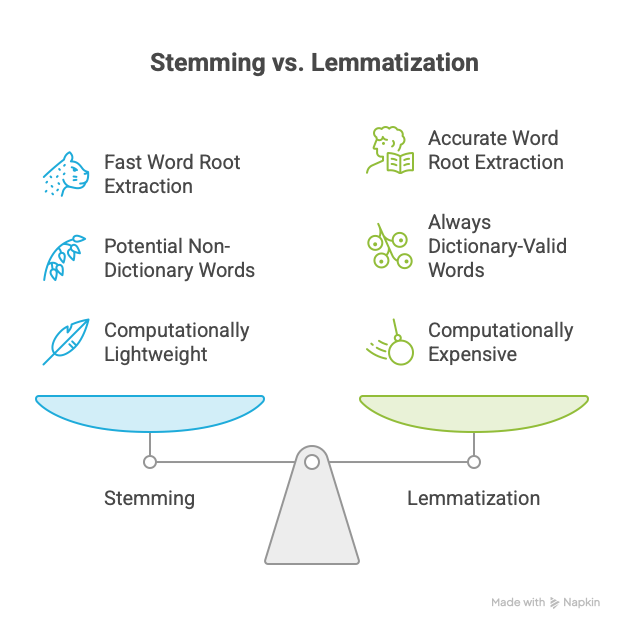

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Stemming vs. lemmatization in code.** The *Porter* stemmer (1980) applies a cascade of suffix-stripping rules; *Snowball* ("Porter2") is its improved, multilingual successor (also available for German: `SnowballStemmer("german")`). Typical stemming errors are **over-stemming** (different words collapse: *universe*, *university* → *univers*) and **under-stemming** (related forms stay apart: *ran* ≠ *run*). The lemmatizer fixes many of these cases, but only if the POS is right.

In [6]:
# [ADDED]
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer

porter, snowball, wnl = PorterStemmer(), SnowballStemmer("english"), WordNetLemmatizer()
words = [("studies", "n"), ("studying", "v"), ("ran", "v"), ("was", "v"), ("better", "a"),
         ("generously", "r"), ("university", "n"), ("universe", "n")]

rows = [{"word": w, "Porter": porter.stem(w), "Snowball": snowball.stem(w),
         "lemma (default: noun)": wnl.lemmatize(w), f"lemma (correct POS)": wnl.lemmatize(w, pos=p)}
        for w, p in words]
display(pd.DataFrame(rows).set_index("word"))

,Porter,Snowball,lemma (default: noun),lemma (correct POS)
word,,,,
studies,studi,studi,study,study
studying,studi,studi,studying,study
ran,ran,ran,ran,run
was,wa,was,wa,be
better,better,better,better,good
generously,gener,generous,generously,generously
university,univers,univers,university,university
universe,univers,univers,universe,universe


In [7]:
# [ADDED]
# POS-aware lemmatization of a sentence: map Penn-Treebank tags to WordNet POS
def wordnet_pos(tag):
    return {"J": "a", "V": "v", "R": "r"}.get(tag[0], "n")

sentence = "The striped bats were hanging on their feet and ate better fruits"
tokens = word_tokenize(sentence.lower())
print("Porter     :", [porter.stem(t) for t in tokens])
print("Lemma (POS):", [wnl.lemmatize(t, wordnet_pos(tag)) for t, tag in nltk.pos_tag(tokens)])

Porter     : ['the', 'stripe', 'bat', 'were', 'hang', 'on', 'their', 'feet', 'and', 'ate', 'better', 'fruit']
Lemma (POS): ['the', 'striped', 'bat', 'be', 'hang', 'on', 'their', 'foot', 'and', 'eat', 'good', 'fruit']


## (iv) Bag-of-Words model



Bag-of-Words is simply just an unstructured count of all known words in a given text. Typically you start by identifying the list of unique words in your text (your vocabulary). So e.g. for the sentence "what big big eyes you have grandma" you could identify your list of unique words as follows:

In [8]:
sentence = "what big big eyes you have grandma"

# Split into words
words = sentence.split()

# Remove duplicates
vocabulary = []
for word in words:
  if word not in vocabulary:
    vocabulary.append(word)
print(vocabulary)

['what', 'big', 'eyes', 'you', 'have', 'grandma']


At this point we can create what's called a document vector, where the document is the text you're analyzing. This is where the actual number of each word in your vocabulary is stored. So for our example, this could be done as so:

In [9]:
documentVector = []
for word in vocabulary:
  documentVector.append(words.count(word))
print(documentVector)

[1, 2, 1, 1, 1, 1]


<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *typo fixed*

Note that the index of each number is equal to the corresponding words index in the vocabulary.

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *typos fixed; the most important drawbacks (3–5) were missing*

One of the main use cases for Bag-of-Words is document classification under the assumption that the high frequency words in any given document will be representative of the main ideas in that document.

However, since Bag-of-Words is just a count of each unique word in a document, this unstructured approach comes with a number of drawbacks. Namely the following:
1. Compound words / multi-word expressions: Some words consist of two different words. Phrases like Mr. Dawson would appear as two different words.
2. Polysemous words: Some words have multiple, vastly different meanings. Words like bat can be both an animal or a sports instrument.
<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

3. **Word order is lost**: *"dog bites man"* and *"man bites dog"* get the same vector (n-grams restore local order only).
4. **High-dimensional and sparse**: one column per vocabulary word (often 10⁴–10⁶), almost all entries 0 → stored as sparse matrices.
5. **Unseen words**: words that are not in the training vocabulary are silently ignored at prediction time.


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

### Bag-of-Words with scikit-learn: `CountVectorizer`

For a corpus of $n$ documents and a vocabulary of size $|V|$, BoW produces a document–term matrix $X\in\mathbb{N}^{n\times |V|}$ with $X_{d,t} = $ count of term $t$ in document $d$.

- `fit` learns the vocabulary, `transform` counts. **Fit on the training set only** and only `transform` validation/test data – otherwise the test vocabulary leaks into the feature space (in cross-validation: put the vectorizer into a `Pipeline`).
- The result is a **sparse** SciPy CSR matrix; do not call `.toarray()` on real corpora.
- Useful options: `lowercase=True` (default), `stop_words="english"`, `min_df`/`max_df` (drop very rare/very frequent words), `binary=True` (presence instead of counts), `ngram_range=(1, 2)` (add bigrams such as *"not good"* – partially recovers word order at the price of a much larger vocabulary).

In [10]:
# [ADDED]
from sklearn.feature_extraction.text import CountVectorizer

train_docs = ["The movie was good, really good!",
              "The movie was not good.",
              "A boring movie with a weak plot."]
test_docs  = ["A good plot, but a terrible ending."]          # 'terrible', 'ending', 'but' are unseen

cv = CountVectorizer()                      # fit vocabulary on TRAIN only
X_train = cv.fit_transform(train_docs)
X_test  = cv.transform(test_docs)           # unseen words are ignored
print(type(X_train).__name__, X_train.shape,
      f"-> {X_train.nnz} non-zeros, sparsity = {1 - X_train.nnz / np.prod(X_train.shape):.0%}")
display(pd.DataFrame(np.vstack([X_train.toarray(), X_test.toarray()]),     # .toarray() only for a toy corpus
                     columns=cv.get_feature_names_out(),
                     index=["train 1", "train 2", "train 3", "test 1"]))

cv2 = CountVectorizer(ngram_range=(1, 2)).fit(train_docs)
print("vocabulary size: unigrams =", len(cv.vocabulary_), "| uni+bigrams =", len(cv2.vocabulary_))
print("e.g. bigrams:", [t for t in cv2.get_feature_names_out() if " " in t][:6])

csr_matrix (3, 10) -> 15 non-zeros, sparsity = 50%


,boring,good,movie,not,plot,really,the,was,weak,with
train 1,0,2,1,0,0,1,1,1,0,0
train 2,0,1,1,1,0,0,1,1,0,0
train 3,1,0,1,0,1,0,0,0,1,1
test 1,0,1,0,0,1,0,0,0,0,0


vocabulary size: unigrams = 10 | uni+bigrams = 21
e.g. bigrams: ['boring movie', 'good really', 'movie was', 'movie with', 'not good', 'really good']


## (v) TF–IDF

<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *'zero weight' holds only for the unsmoothed textbook IDF; heading levels fixed*

### What is TF-IDF?

TF-IDF stands for Term Frequency - Inverse Document Frequency. It is a way for computers to figure out which words are the most important in a document. Instead of just counting how often the word appears, TF-IDF measures a word’s informational weight and importance within the document.


### How does TF-IDF work?

This algorithm evaluates the words within two dimensions: (1) frequency and (2) rarity.


1. Term Frequency (TF): How often does the word appear here?

    * If a word appears many times in a single article, it is probably important to that article.
    * Example: In an article about baking, the word "flour" might appear 15 times.


2. Inverse Document Frequency (IDF): How rare is the word everywhere else?

    * If a word appears in almost every document you own, it is not special to any single one.
    * Example: Words like "the", "is", and "and" appear everywhere, so they carry almost no information about a specific document. <span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *With the textbook IDF they get weight exactly 0; with scikit-learn's smoothed IDF (below) they get the minimum weight 1, i.e. they are down-weighted, not removed (use `stop_words` / `max_df` to remove them).*


A word gets a high score if it appears frequently in one specific document, but rarely across all other documents.


### What are the applications of TF-IDF?

**Document similarity and clustering:** TF-IDF enables comparison and grouping of related texts. This is valuable for clustering news articles, research papers or customer support tickets into categories.


**Keyword Extraction:** It ranks words by importance making it possible to automatically highlight key terms, generate document tags or create concise summaries.


**Recommendation Systems:** Through comparison of textual descriptions TF-IDF supports suggesting related articles, videos or products enhancing user engagement.



<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

### TF–IDF formulas: textbook vs. scikit-learn

Let $n$ = number of documents, $\mathrm{tf}(t,d)$ = count of term $t$ in document $d$, and $\mathrm{df}(t)$ = number of documents containing $t$.

**Textbook definition**
$$\mathrm{tfidf}(t,d) = \mathrm{tf}(t,d)\cdot \log\frac{n}{\mathrm{df}(t)} \qquad(\text{a term in every document gets } \log 1 = 0)$$

**scikit-learn `TfidfVectorizer` default** (`smooth_idf=True`, `norm="l2"`, natural log):
$$\mathrm{idf}(t) = \ln\frac{1+n}{1+\mathrm{df}(t)} + 1, \qquad \tilde{x}_{d,t} = \mathrm{tf}(t,d)\cdot \mathrm{idf}(t), \qquad x_{d} = \frac{\tilde{x}_{d}}{\lVert \tilde{x}_{d}\rVert_2}$$

- The "+1" inside the fraction acts as if one extra document contained every term once (no division by zero for unseen terms); the "+1" outside keeps terms that occur in all documents (weight 1 instead of 0).
- With `smooth_idf=False`: $\mathrm{idf}(t)=\ln\frac{n}{\mathrm{df}(t)}+1$. With `sublinear_tf=True`: $\mathrm{tf}\to 1+\ln \mathrm{tf}$.
- L2 normalization makes every document vector unit length, so long and short documents become comparable and the dot product of two rows equals their **cosine similarity**.
- The IDF is a corpus statistic: it is learned in `fit` → **fit on the training set only**.

The cell below recomputes scikit-learn's result by hand on a tiny corpus.

In [11]:
# [ADDED]
from sklearn.feature_extraction.text import TfidfVectorizer

corpus = ["the cat sat on the mat",
          "the dog sat on the log",
          "the cat chased the dog"]

tfidf = TfidfVectorizer()                         # defaults: smooth_idf=True, norm="l2"
X = tfidf.fit_transform(corpus).toarray()
terms = tfidf.get_feature_names_out()

# --- manual computation ---------------------------------------------------
counts = CountVectorizer(vocabulary=terms).fit_transform(corpus).toarray()   # tf(t, d)
n  = counts.shape[0]
df = (counts > 0).sum(axis=0)                     # document frequency
idf_textbook = np.log(n / df)
idf_sklearn  = np.log((1 + n) / (1 + df)) + 1
X_manual = counts * idf_sklearn
X_manual = X_manual / np.linalg.norm(X_manual, axis=1, keepdims=True)

display(pd.DataFrame({"df": df, "idf textbook": idf_textbook, "idf sklearn": idf_sklearn,
                      "tfidf.idf_": tfidf.idf_}, index=terms).round(3).T)
display(pd.DataFrame(X, columns=terms, index=["doc 1", "doc 2", "doc 3"]).round(3))
print("manual == sklearn:", np.allclose(X, X_manual))
print("row norms:", np.linalg.norm(X, axis=1).round(6))
print("cosine similarity doc1·doc2 =", round(X[0] @ X[1], 3), "| doc1·doc3 =", round(X[0] @ X[2], 3))

,cat,chased,dog,log,mat,on,sat,the
df,2.000,1.000,2.000,1.000,1.000,2.000,2.000,3.0
idf textbook,0.405,1.099,0.405,1.099,1.099,0.405,0.405,0.0
idf sklearn,1.288,1.693,1.288,1.693,1.693,1.288,1.288,1.0
tfidf.idf_,1.288,1.693,1.288,1.693,1.693,1.288,1.288,1.0


,cat,chased,dog,log,mat,on,sat,the
doc 1,0.374,0.000,0.000,0.000,0.492,0.374,0.374,0.581
doc 2,0.000,0.000,0.374,0.492,0.000,0.374,0.374,0.581
doc 3,0.404,0.531,0.404,0.000,0.000,0.000,0.000,0.627


manual == sklearn: True
row norms: [1. 1. 1.]
cosine similarity doc1·doc2 = 0.618 | doc1·doc3 = 0.515


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Leakage-free usage.** Put the vectorizer and the model into one `Pipeline`; then `fit` (and every cross-validation fold) learns vocabulary and IDF from the training part only, and `predict` applies the same transformation to new text.

In [12]:
# [ADDED]
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

X_txt = ["free money, click now", "win a free prize now", "cheap meds, limited offer",
         "meeting moved to monday", "please review the report", "lunch with the team tomorrow"]
y = ["spam", "spam", "spam", "ham", "ham", "ham"]

clf = make_pipeline(TfidfVectorizer(preprocessor=clean_text), LogisticRegression())
clf.fit(X_txt, y)
print(clf.predict(["Claim your FREE prize now!!!", "Can we review the report on Monday?"]))

['spam' 'ham']


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

## Takeaways

- **What should every ML practitioner remember?**
  - Classical text encoding is a pipeline: *clean (regex) → tokenize → normalize (stem/lemmatize) → vectorize (BoW / TF–IDF)*; every step is a modelling decision that changes the vocabulary.
  - Stemming = fast, rule-based suffix stripping (may give non-words: *studies* → *studi*); lemmatization = dictionary + POS → valid lemma (*better* → *good* only with POS = adjective).
  - BoW = document–term count matrix (sparse, order-free); TF–IDF re-weights counts by $\mathrm{idf}$. scikit-learn default: $\mathrm{idf}=\ln\frac{1+n}{1+\mathrm{df}}+1$ followed by L2 row normalization (dot product = cosine similarity).
- **What are common pitfalls?**
  - Fitting `CountVectorizer`/`TfidfVectorizer` (vocabulary, IDF) on the full data set → leakage; fit on train only, use a `Pipeline` for CV.
  - Over-aggressive cleaning: removing punctuation, numbers, negations ("not") or casing can destroy the signal (sentiment, prices, *US* vs. *us*); `[a-zA-Z]` silently drops umlauts.
  - Hidden defaults: sklearn's `token_pattern` drops 1-character tokens; `WordNetLemmatizer` assumes nouns; smoothed IDF does not remove frequent words.
  - Calling `.toarray()` on a large sparse matrix (memory explosion); huge vocabularies from n-grams without `min_df`/`max_features`.
  - Train and test text must go through **exactly the same** preprocessing function.
- **When does this technique really matter?**
  - Small/medium labelled data sets, need for speed and interpretability (spam filters, ticket routing, keyword extraction, search/retrieval): TF–IDF + linear model is a strong baseline that is hard to beat.
  - Stemming/lemmatization matter most for small corpora and morphologically rich languages (e.g. German); with large data or subword-tokenized neural models (BERT, GPT) they are usually unnecessary.
  - When word order or context is essential (negation, sarcasm, long-range meaning), BoW/TF–IDF reach their limit → n-grams or embeddings (Text Encoding II).

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *empty item removed; references 11–15 added*

## References

*Cite the sources of all figures, diagrams and code snippets (URLs are sufficient).*

1. https://www.ibm.com/think/topics/bag-of-words
2. https://machinelearningmastery.com/gentle-introduction-bag-words-model/
3. https://www.geeksforgeeks.org/python/python-spilt-a-sentence-into-list-of-words/
4. https://www.geeksforgeeks.org/python/python-ways-to-remove-duplicates-from-list/
5. https://www.geeksforgeeks.org/python/python-count-occurrences-element-list/
6. https://medium.com/@morepravin1989/understanding-feature-normalization-in-machine-learning-a-beginners-guide-79a62ed03511
7. https://www.ibm.com/think/topics/stemming
8. https://www.ibm.com/think/topics/stemming-lemmatization
9. https://www.ibm.com/think/topics/tokenization
10. https://huggingface.co/learn/llm-course/chapter6/5

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

11. Python docs, `re` – Regular expression operations: https://docs.python.org/3/library/re.html
12. NLTK, `nltk.stem` (Porter, Snowball, WordNet lemmatizer): https://www.nltk.org/api/nltk.stem.html
13. scikit-learn User Guide, Text feature extraction (BoW, TF–IDF, smoothing): https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
14. scikit-learn API, `TfidfTransformer`: https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html
15. Manning, Raghavan, Schütze, *Introduction to Information Retrieval*, Ch. 2 & 6: https://nlp.stanford.edu/IR-book/
